# Phase 1 · Thu thập & Khám phá dữ liệu
**CSC17104 – In-Vehicle Coupon Acceptance** · Trần Nhật Dương (Thu thập dữ liệu) · Nguyễn Mạnh Hà (Khám phá dữ liệu)

Notebook trả lời lần lượt từng câu hỏi của đề ở bước **1. Collecting data** và **2. Exploring data**, sau đó chốt kế hoạch tiền xử lý dùng chung cho Phase 2 (`02_analysis.ipynb`, câu Q1–Q5) và Phase 3 (`03_ml_question.ipynb`, câu Q6).

**Mục lục** *(dùng bảng Table of Contents của Jupyter để di chuyển nhanh)*
1. Thu thập dữ liệu — 1.1 Chủ đề & nguồn · 1.2 Giấy phép · 1.3 Cách thu thập · 1.4 Lý do chọn
2. Khám phá dữ liệu — 2.1 Số dòng/cột · 2.2 Ý nghĩa mỗi dòng · 2.3 Dòng trùng lặp · 2.4 Ý nghĩa mỗi cột · 2.5 Kiểu dữ liệu · 2.6 Cột số · 2.7 Cột phân loại · 2.8 Quan hệ sơ bộ · 2.9 Biến dẫn xuất · 2.10 Nhận xét & kế hoạch tiền xử lý

## 1. Thu thập dữ liệu *(Trần Nhật Dương)*

### 1.1. Dữ liệu nói về chủ đề gì? Nguồn ở đâu?
- **Chủ đề:** ý định chấp nhận một **coupon** (phiếu ưu đãi của quán bar, quán cà phê, nhà hàng, đồ ăn mang đi) được gợi ý cho người **đang lái xe**. Mỗi tình huống mô tả bối cảnh hành trình (điểm đến, người đi cùng, thời tiết, giờ, thời gian lái và hướng đến quán), loại coupon và thời hạn, kèm hồ sơ cá nhân và thói quen ăn uống của người trả lời.
- **Nguồn:** UCI Machine Learning Repository – Dataset **#603** *In-Vehicle Coupon Recommendation* (<https://archive.ics.uci.edu/dataset/603/in+vehicle+coupon+recommendation>), DOI `10.24432/C5GS4P`.
- **Bài báo gốc:** Wang, T., Rudin, C., Doshi-Velez, F., Liu, Y., Klampfl, E., & MacNeille, P. (2017). *A Bayesian Framework for Learning Rule Sets for Interpretable Classification*. JMLR 18(70), 1–37.

### 1.2. Tác giả có cho phép sử dụng dữ liệu như nhóm đang làm không?
- Dữ liệu phát hành theo giấy phép **Creative Commons Attribution 4.0 (CC BY 4.0)**: được sao chép, phân tích, chỉnh sửa và dùng cho mọi mục đích (kể cả học thuật) với điều kiện **ghi nguồn** tác giả/UCI.
- Nhóm tuân thủ bằng cách giữ nguyên file gốc trong `data/raw/` (không sửa, không phát tán bản đã chỉnh) và ghi nguồn tại notebook này và `README.md`.

### 1.3. Tác giả đã thu thập dữ liệu như thế nào?
- Theo mô tả của UCI, dữ liệu được thu thập qua **khảo sát trên Amazon Mechanical Turk**: bảng hỏi mô tả nhiều tình huống lái xe (điểm đến, giờ hiện tại, thời tiết, người đi cùng, …) rồi hỏi người trả lời **có nhận coupon hay không nếu họ là tài xế**.
- Hệ quả cần nhớ khi phân tích: (1) `Y = 1` là **ý định tự khai** trong tình huống giả định, không phải giao dịch đổi coupon thật; (2) mỗi người trả lời nhiều tình huống nhưng file **không có mã người trả lời**; (3) người trả lời là lao động MTurk nên không đại diện cho mọi tài xế; (4) tổ hợp bối cảnh do người thiết kế khảo sát chọn nên có các ô rỗng cấu trúc (mục 2.8).

### 1.4. Vì sao nhóm chọn bộ dữ liệu này?
- Dữ liệu thật, công khai, giấy phép rõ ràng; quy mô `12.684` dòng × `26` cột vượt yêu cầu tối thiểu của đề.
- Đủ nhóm biến (bối cảnh, ưu đãi, nhân khẩu học, thói quen, nhãn nhị phân) để đặt câu hỏi có ích cho bài toán thực tế *gợi ý ưu đãi trong ứng dụng dẫn đường*, trả lời được bằng cả phân tích thống kê (Q1–Q5) lẫn Machine Learning (Q6).
- Có những khó khăn thật để luyện cách làm đúng: thiếu mã người trả lời, cột `car` gần như rỗng, nhiều ô rỗng do thiết kế khảo sát.

In [1]:
import sys
from pathlib import Path

# Cho phép import gói coupon_project trong src/ dù mở notebook từ thư mục gốc hay notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import hashlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from coupon_project.data import (
    DATA_PROCESSED_DIR, RAW_CSV_PATH, audit_row, load_raw_data, missing_table,
    save_table, target_is_binary,
)
from coupon_project.features import (
    AGE_ORDER, COUPON_FREQUENCY, DESTINATIONS, EXPIRATION_ORDER, FREQUENCIES,
    INCOME_ORDER, PASSENGERS, TIME_ORDER, matched_frequency,
)
from coupon_project.plotting import save_figure, set_style
from coupon_project.stats import rate_table, wilson_ci

set_style()
df = load_raw_data(RAW_CSV_PATH)  # đọc nguyên bản, không bỏ dòng hay điền ô trống nào
assert target_is_binary(df)

# Mã băm SHA-256 giúp cả nhóm xác nhận đang phân tích đúng cùng một file gốc
raw_sha = hashlib.sha256(RAW_CSV_PATH.read_bytes()).hexdigest()
print(f"File gốc: {RAW_CSV_PATH.name} | SHA-256: {raw_sha[:16]}...")

File gốc: in-vehicle-coupon-recommendation.csv | SHA-256: d47897367f5a12a3...


## 2. Khám phá dữ liệu *(Nguyễn Mạnh Hà)*
Mỗi mục dưới đây trả lời đúng một câu hỏi khám phá của đề. Vấn đề phát hiện được ghi ngay tại mục đó và tổng hợp thành kế hoạch tiền xử lý ở mục 2.10.

### 2.1. Dữ liệu có bao nhiêu dòng và bao nhiêu cột?

In [2]:
n_rows, n_cols = df.shape
print(f"Số dòng: {n_rows:,} | Số cột: {n_cols} (25 đặc trưng + nhãn Y)")

Số dòng: 12,684 | Số cột: 26 (25 đặc trưng + nhãn Y)


→ Dữ liệu có **12.684 dòng** và **26 cột** (25 đặc trưng + nhãn `Y`).

### 2.2. Mỗi dòng có ý nghĩa gì?
Mỗi dòng là **câu trả lời của một người cho một tình huống lái xe giả định**: bối cảnh hành trình + loại coupon và thời hạn + hồ sơ, thói quen của người trả lời + nhãn `Y` (`1` = sẽ nhận coupon, `0` = từ chối). Một dòng **không phải một người**: mỗi người trả lời nhiều tình huống (Phase 2.3 suy ra `567` người, phần lớn có đúng `22` dòng). Ba dòng đầu (xoay ngang để dễ đọc):

In [3]:
display(df.head(3).T)

,0,1,2
destination,No Urgent Place,No Urgent Place,No Urgent Place
passanger,Alone,Friend(s),Friend(s)
weather,Sunny,Sunny,Sunny
temperature,55,80,80
time,2PM,10AM,10AM
coupon,Restaurant(<20),Coffee House,Carry out & Take away
expiration,1d,2h,2h
gender,Female,Female,Female
age,21,21,21
maritalStatus,Unmarried partner,Unmarried partner,Unmarried partner


### 2.3. Có dòng nào bị trùng lặp không?

In [4]:
dup_extra = df.duplicated()          # True cho bản sao thứ 2 trở đi của một dòng
dup_all = df.duplicated(keep=False)  # True cho mọi dòng nằm trong một nhóm trùng
print(f"Bản sao thừa: {dup_extra.sum()} dòng ({dup_extra.mean() * 100:.2f}%)")
print(f"Số dòng thuộc các nhóm trùng: {dup_all.sum()}")
group_sizes = df[dup_all].groupby(list(df.columns), dropna=False).size()
print("Kích thước nhóm trùng -> số nhóm:", group_sizes.value_counts().to_dict())

# Xếp các dòng trùng cạnh nhau để thấy chúng giống hệt nhau ở cả 26 cột
display(df[dup_all].sort_values(list(df.columns)).head(4))

Bản sao thừa: 74 dòng (0.58%)
Số dòng thuộc các nhóm trùng: 148
Kích thước nhóm trùng -> số nhóm: {2: 74}


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
6968,Home,Alone,Snowy,30,10PM,Restaurant(20-50),2h,Female,31,Married partner,...,less1,gt8,4~8,less1,1,0,0,0,1,0
7853,Home,Alone,Snowy,30,10PM,Restaurant(20-50),2h,Female,31,Married partner,...,less1,gt8,4~8,less1,1,0,0,0,1,0
7407,Home,Alone,Snowy,30,6PM,Coffee House,1d,Male,46,Married partner,...,1~3,1~3,less1,1~3,1,1,0,0,1,0
8509,Home,Alone,Snowy,30,6PM,Coffee House,1d,Male,46,Married partner,...,1~3,1~3,less1,1~3,1,1,0,0,1,0


→ Có **74 bản sao thừa** (`0,58%`), mỗi nhóm trùng gồm đúng 2 dòng giống hệt nhau ở cả 26 cột. Vì file không có mã người trả lời, nhóm **không thể biết** đây là lỗi nhập liệu hay hai câu trả lời hợp lệ (hai người cùng hồ sơ, hoặc một người gặp lại cùng tình huống). **Quyết định:** giữ nguyên ở bản phân tích chính và kiểm tra độ nhạy khi bỏ trùng ở Q1 và Q3 (Phase 2).

### 2.4. Mỗi cột có ý nghĩa gì?
Theo mô tả biến của UCI (giữ nguyên tên cột gốc, kể cả lỗi chính tả `passanger`):

| Cột | Nhóm | Ý nghĩa |
| --- | --- | --- |
| `destination` | Bối cảnh | Điểm đến hiện tại: `No Urgent Place`, `Home`, `Work` |
| `passanger` | Bối cảnh | Người đi cùng: `Alone`, `Friend(s)`, `Kid(s)`, `Partner` |
| `weather` | Bối cảnh | Thời tiết: `Sunny`, `Rainy`, `Snowy` |
| `temperature` | Bối cảnh | Nhiệt độ (°F): `30`, `55`, `80` |
| `time` | Bối cảnh | Giờ trong ngày: `7AM`, `10AM`, `2PM`, `6PM`, `10PM` (không phải ngày tháng) |
| `coupon` | Ưu đãi | Loại coupon: `Bar`, `Coffee House`, `Carry out & Take away`, `Restaurant(<20)`, `Restaurant(20-50)` (chi phí trung bình/người < 20 USD hoặc 20–50 USD) |
| `expiration` | Ưu đãi | Thời hạn coupon: `2h` (2 giờ) hoặc `1d` (1 ngày) |
| `gender`, `maritalStatus`, `education`, `occupation` | Hồ sơ | Giới tính, tình trạng hôn nhân, học vấn, nghề nghiệp |
| `age` | Hồ sơ | Mã nhóm tuổi: `below21`, `21`, `26`, …, `46`, `50plus` (mỗi mã là mốc đầu của nhóm) |
| `has_children` | Hồ sơ | Người trả lời có con hay không (`1`/`0`) |
| `income` | Hồ sơ | Khoảng thu nhập năm (9 khoảng USD) |
| `car` | Hồ sơ | Loại xe đang dùng |
| `Bar`, `CoffeeHouse`, `CarryAway` | Thói quen | Số lần mỗi tháng đi bar / đến quán cà phê / mua đồ ăn mang đi: `never`, `less1`, `1~3`, `4~8`, `gt8` |
| `RestaurantLessThan20`, `Restaurant20To50` | Thói quen | Số lần mỗi tháng ăn nhà hàng có chi phí/người < 20 USD / 20–50 USD (cùng thang) |
| `toCoupon_GEQ5min`, `toCoupon_GEQ15min`, `toCoupon_GEQ25min` | Khoảng cách | Lái xe đến quán dùng coupon mất ≥ 5 / ≥ 15 / ≥ 25 phút (`1`/`0`) |
| `direction_same`, `direction_opp` | Hướng | Quán nằm cùng hướng / ngược hướng với điểm đến hiện tại (`1`/`0`) |
| `Y` | Nhãn | Người trả lời có nhận coupon không (`1` = nhận, `0` = từ chối) |

### 2.5. Kiểu dữ liệu hiện tại của mỗi cột là gì? Có cột nào kiểu chưa phù hợp không?

In [5]:
binary_cols = ["has_children", "toCoupon_GEQ5min", "toCoupon_GEQ15min",
               "toCoupon_GEQ25min", "direction_same", "direction_opp", "Y"]
ordered_cols = ["age", "income", "time", "expiration"] + list(COUPON_FREQUENCY.values())


def semantic_type(col):
    """Kiểu dữ liệu theo ý nghĩa (khác với kiểu lưu trữ dtype của pandas)."""
    if col in binary_cols:
        return "binary 0/1"
    if col == "temperature":
        return "số rời rạc (3 mức)"
    if col in ordered_cols:
        return "phân loại có thứ tự"
    return "phân loại không thứ tự"


schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "semantic_type": [semantic_type(c) for c in df.columns],
})
save_table(schema.reset_index(names="column"), "eda_schema")
display(schema)
print("Số cột theo dtype:", schema["dtype"].value_counts().to_dict())

# Sắp xếp theo chuỗi làm sai thứ tự tự nhiên của các cột có thứ tự
print("time sắp theo chuỗi:", sorted(df["time"].unique()))
print("income sắp theo chuỗi (3 mức đầu):", sorted(df["income"].unique())[:3])

,dtype,n_unique,missing_pct,semantic_type
destination,str,3,0.00,phân loại không thứ tự
passanger,str,4,0.00,phân loại không thứ tự
weather,str,3,0.00,phân loại không thứ tự
temperature,int64,3,0.00,số rời rạc (3 mức)
time,str,5,0.00,phân loại có thứ tự
coupon,str,5,0.00,phân loại không thứ tự
expiration,str,2,0.00,phân loại có thứ tự
gender,str,2,0.00,phân loại không thứ tự
age,str,8,0.00,phân loại có thứ tự
maritalStatus,str,5,0.00,phân loại không thứ tự


Số cột theo dtype: {'str': 18, 'int64': 8}
time sắp theo chuỗi: ['10AM', '10PM', '2PM', '6PM', '7AM']
income sắp theo chuỗi (3 mức đầu): ['$100000 or More', '$12500 - $24999', '$25000 - $37499']


→ `pandas` đọc **18 cột dạng chuỗi** và **8 cột số nguyên**. Không cột nào sai kiểu đến mức làm hỏng phép tính, nhưng có các cột **cần đổi cách biểu diễn khi phân tích**:
- `age`, `income`, `time`, `expiration` và 5 cột thói quen là **phân loại có thứ tự** nhưng đang lưu dạng chuỗi: sắp xếp theo chuỗi cho thứ tự sai (`10AM` đứng trước `7AM`; `$100000 or More` đứng trước `$12500 - $24999`) → dùng `pd.Categorical(..., ordered=True)` với thứ tự định nghĩa trong `coupon_project.features` (`TIME_ORDER`, `AGE_ORDER`, `INCOME_ORDER`, `FREQUENCIES`).
- `age`, `income` **không ép sang số** vì là mã nhóm/khoảng (`below21`, `50plus`, `$100000 or More`).
- `temperature` là số nhưng chỉ có 3 mức → coi như biến phân loại (Q6 mã hóa One-Hot).
- Các cột 0/1 để kiểu `int64` là phù hợp (tính tỷ lệ bằng `mean`).

### 2.6. Với mỗi cột số: giá trị phân bố thế nào? Bao nhiêu % bị thiếu? Min/max có bất thường không?

In [6]:
num_cols = df.select_dtypes("number").columns
num_summary = pd.DataFrame({
    "missing_pct": df[num_cols].isna().mean().mul(100).round(2),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
    "mean": df[num_cols].mean().round(3),  # với cột 0/1, mean = tỷ lệ giá trị 1
    "values": [sorted(df[c].unique().tolist()) for c in num_cols],
})
save_table(num_summary.reset_index(names="column"), "eda_numeric_summary")
display(num_summary)

# Kiểm tra logic giữa các cột: số vi phạm phải bằng 0 nếu dữ liệu hợp lệ
geq25, geq15, geq5 = df["toCoupon_GEQ25min"], df["toCoupon_GEQ15min"], df["toCoupon_GEQ5min"]
checks = pd.DataFrame([
    {"check": "GEQ25=1 nhưng GEQ15=0", "violations": int(((geq25 == 1) & (geq15 == 0)).sum())},
    {"check": "GEQ15=1 nhưng GEQ5=0", "violations": int(((geq15 == 1) & (geq5 == 0)).sum())},
    {"check": "direction_same + direction_opp != 1",
     "violations": int((df["direction_same"] + df["direction_opp"] != 1).sum())},
    {"check": "temperature ngoài {30, 55, 80}",
     "violations": int((~df["temperature"].isin([30, 55, 80])).sum())},
])
display(checks)
assert checks["violations"].sum() == 0
print("Cột hằng số:", [c for c in num_cols if df[c].nunique() == 1])
display(pd.crosstab(df["weather"], df["temperature"]))  # nhiệt độ gắn với thời tiết

,missing_pct,min,max,mean,values
temperature,0.0,30,80,63.302,"[30, 55, 80]"
has_children,0.0,0,1,0.414,"[0, 1]"
toCoupon_GEQ5min,0.0,1,1,1.000,[1]
toCoupon_GEQ15min,0.0,0,1,0.561,"[0, 1]"
toCoupon_GEQ25min,0.0,0,1,0.119,"[0, 1]"
direction_same,0.0,0,1,0.215,"[0, 1]"
direction_opp,0.0,0,1,0.785,"[0, 1]"
Y,0.0,0,1,0.568,"[0, 1]"


,check,violations
0,GEQ25=1 nhưng GEQ15=0,0
1,GEQ15=1 nhưng GEQ5=0,0
2,direction_same + direction_opp != 1,0
3,"temperature ngoài {30, 55, 80}",0


Cột hằng số: ['toCoupon_GEQ5min']


temperature,30,55,80
weather,,,
Rainy,0,1210,0
Snowy,1405,0,0
Sunny,911,2630,6528


→ Các cột số **không thiếu giá trị** và đều nằm trong miền hợp lệ (cờ 0/1; `temperature` ∈ {30, 55, 80}); **0 vi phạm** logic giữa các cờ khoảng cách và hướng. Điểm bất thường cần xử lý:
- `toCoupon_GEQ5min` **luôn bằng 1** (cột hằng, không mang thông tin) → không dùng làm đặc trưng.
- `direction_opp` luôn bằng `1 − direction_same` (trùng thông tin) → chỉ giữ `direction_same`.
- `temperature` phụ thuộc `weather` (`Rainy` luôn 55°F, `Snowy` luôn 30°F) → đặc điểm thiết kế khảo sát, không phải lỗi.

### 2.7. Với mỗi cột phân loại: giá trị phân bố thế nào? Bao nhiêu % bị thiếu? Có bao nhiêu giá trị khác nhau? Có giá trị bất thường không?

In [7]:
cat_cols = df.select_dtypes(exclude="number").columns


def top_values(series, k=3):
    """Liệt kê k giá trị phổ biến nhất kèm tỷ lệ (%) – để 'xem thử vài giá trị'."""
    shares = series.value_counts(normalize=True).head(k).mul(100).round(1)
    return "; ".join(f"{value} ({share}%)" for value, share in shares.items())


cat_summary = pd.DataFrame({
    "missing_pct": df[cat_cols].isna().mean().mul(100).round(2),
    "n_unique": df[cat_cols].nunique(),
    "top_values": [top_values(df[c]) for c in cat_cols],
})
save_table(cat_summary.reset_index(names="column"), "eda_categorical_summary")
display(cat_summary)

# Giá trị bất thường: nhãn nằm ngoài danh mục mong đợi hoặc có khoảng trắng thừa
expected_labels = {col: FREQUENCIES for col in COUPON_FREQUENCY.values()}
expected_labels.update({
    "age": AGE_ORDER, "income": INCOME_ORDER, "time": TIME_ORDER,
    "expiration": EXPIRATION_ORDER, "coupon": list(COUPON_FREQUENCY),
    "passanger": PASSENGERS, "destination": DESTINATIONS,
})
label_check = pd.DataFrame([
    {"column": col, "unexpected_labels": sorted(set(df[col].dropna()) - set(allowed))}
    for col, allowed in expected_labels.items()
])
display(label_check)
n_spaces = sum(int((df[c].dropna() != df[c].dropna().str.strip()).sum()) for c in cat_cols)
print("Số giá trị có khoảng trắng thừa:", n_spaces)
print("Các giá trị của car:", df["car"].value_counts().to_dict())

,missing_pct,n_unique,top_values
destination,0.00,3,No Urgent Place (49.5%); Home (25.5%); Work (2...
passanger,0.00,4,Alone (57.6%); Friend(s) (26.0%); Partner (8.5%)
weather,0.00,3,Sunny (79.4%); Snowy (11.1%); Rainy (9.5%)
time,0.00,5,6PM (25.5%); 7AM (24.9%); 10AM (17.9%)
coupon,0.00,5,Coffee House (31.5%); Restaurant(<20) (22.0%);...
expiration,0.00,2,1d (55.9%); 2h (44.1%)
gender,0.00,2,Female (51.3%); Male (48.7%)
age,0.00,8,21 (20.9%); 26 (20.2%); 31 (16.1%)
maritalStatus,0.00,5,Married partner (40.2%); Single (37.5%); Unmar...
education,0.00,6,Some college - no degree (34.3%); Bachelors de...


,column,unexpected_labels
0,Bar,[]
1,CoffeeHouse,[]
2,CarryAway,[]
3,RestaurantLessThan20,[]
4,Restaurant20To50,[]
5,age,[]
6,income,[]
7,time,[]
8,expiration,[]
9,coupon,[]


Số giá trị có khoảng trắng thừa: 0
Các giá trị của car: {'Scooter and motorcycle': 22, 'Mazda5': 22, 'do not drive': 22, 'crossover': 21, 'Car that is too old to install Onstar :D': 21}


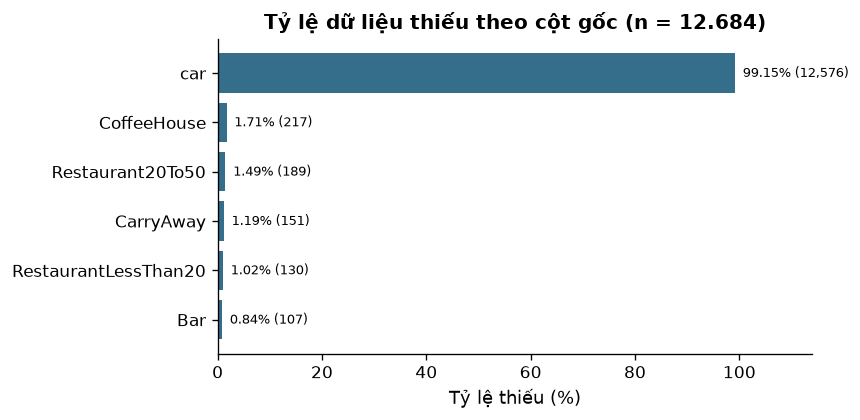

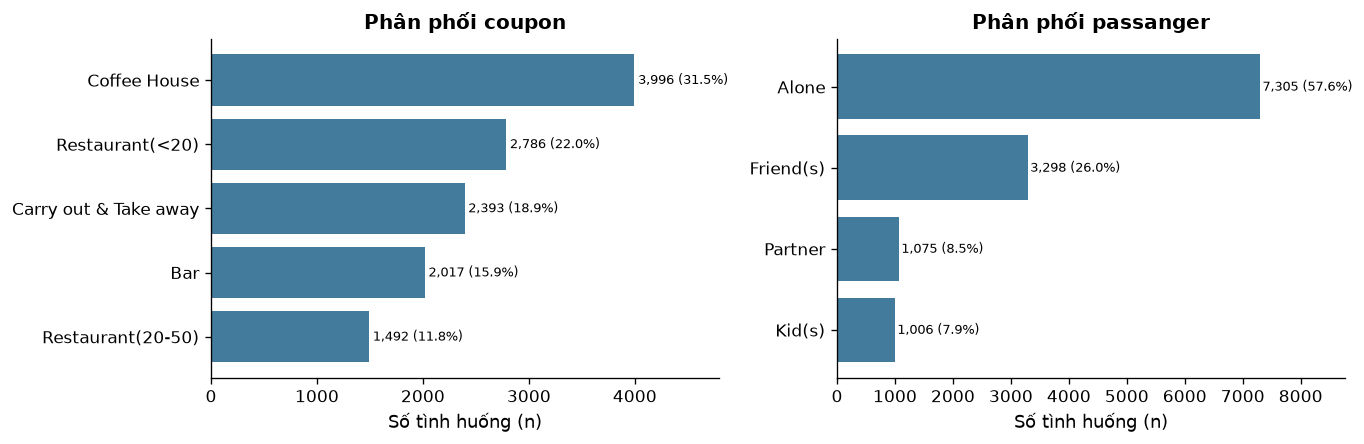

In [8]:
missing = missing_table(df).reset_index(names="column")
save_table(missing, "eda_missing")
n_text = f"{len(df):,}".replace(",", ".")  # viết số theo kiểu Việt Nam: 12.684

fig, ax = plt.subplots(figsize=(7.2, 3.6))
shown = missing[missing["missing_count"] > 0]
ax.barh(shown["column"], shown["missing_pct"], color="#346e8b")
ax.invert_yaxis()
ax.set(xlabel="Tỷ lệ thiếu (%)", xlim=(0, 114),
       title=f"Tỷ lệ dữ liệu thiếu theo cột gốc (n = {n_text})")
for i, r in enumerate(shown.itertuples()):
    ax.text(r.missing_pct + 1.5, i, f"{r.missing_pct:.2f}% ({r.missing_count:,})",
            va="center", fontsize=8)
fig.tight_layout()
save_figure(fig, "eda_missing")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, col in zip(axes, ["coupon", "passanger"]):
    cnt = df[col].value_counts()
    ax.barh(cnt.index, cnt.values, color="#427b9b")
    ax.invert_yaxis()
    ax.set(xlabel="Số tình huống (n)", title=f"Phân phối {col}")
    ax.margins(x=0.2)
    for i, v in enumerate(cnt.values):
        ax.text(v + 35, i, f"{v:,} ({v / len(df) * 100:.1f}%)", va="center", fontsize=8)
fig.tight_layout()
save_figure(fig, "eda_distributions")
plt.show()

→ Nhận xét về các cột phân loại:
- **Thiếu dữ liệu** chỉ xuất hiện ở `car` (**99,15%**) và 5 cột thói quen (**0,84%–1,71%**); các cột còn lại đầy đủ. Đáng chú ý: trang UCI ghi bộ dữ liệu *không có giá trị thiếu*, nhưng file CSV thực tế có — đây là lý do phải tự kiểm tra thay vì tin metadata.
- **Số giá trị khác nhau** từ 2 (`gender`, `expiration`) đến 25 (`occupation`); bảng trên liệt kê 3 giá trị phổ biến nhất của từng cột.
- **Không có nhãn lạ hay khoảng trắng thừa** ở các cột đối chiếu được với danh mục chuẩn (thói quen, tuổi, thu nhập, giờ, thời hạn, coupon, người đi cùng, điểm đến).
- **Bất thường:** `car` gần như rỗng và chứa cả giá trị không phải loại xe (`do not drive`, `Car that is too old to install Onstar :D`) → không dùng `car` làm biến phân tích hay đặc trưng dự đoán (chỉ dùng như một phần khóa hồ sơ để suy ra `respondent_id` ở Phase 2.3 và Phase 3).
- **Phân phối lệch:** `Sunny` chiếm phần lớn `weather`, `Alone` chiếm phần lớn `passanger`, `Coffee House` là coupon phổ biến nhất (tỷ lệ cụ thể ở cột `top_values` và hình phân phối).

### 2.8. Quan hệ sơ bộ giữa các biến (định hướng câu hỏi)

In [9]:
summary_parts = []
for col in ["coupon", "expiration", "destination", "passanger"]:
    rates = rate_table(df, [col])  # n, số nhận, tỷ lệ (%) và Wilson 95% CI theo từng mức
    display(rates)
    summary_parts.append(rates.rename(columns={col: "level"}).assign(variable=col))
summary_cols = ["variable", "level", "n", "accepted", "rate_pct",
                "ci_low_pct", "ci_high_pct", "small_n"]
summary_rates = pd.concat(summary_parts, ignore_index=True)[summary_cols]
save_table(summary_rates, "eda_summary_rates")

# Ô rỗng cấu trúc: tổ hợp bối cảnh không bao giờ xuất hiện trong khảo sát
passenger_dest = pd.crosstab(df["passanger"], df["destination"])
display(passenger_dest.reindex(index=PASSENGERS, columns=DESTINATIONS, fill_value=0))
time_dest = pd.crosstab(df["time"], df["destination"])
display(time_dest.reindex(index=TIME_ORDER, columns=DESTINATIONS, fill_value=0))

,coupon,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,Bar,2017,827,41.00,38.87,43.16,False
1,Carry out & Take away,2393,1760,73.55,71.74,75.28,False
2,Coffee House,3996,1995,49.92,48.38,51.47,False
3,Restaurant(20-50),1492,658,44.10,41.60,46.63,False
4,Restaurant(<20),2786,1970,70.71,68.99,72.37,False


,expiration,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,1d,7091,4436,62.56,61.43,63.68,False
1,2h,5593,2774,49.60,48.29,50.91,False


,destination,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,Home,3237,1639,50.63,48.91,52.35,False
1,No Urgent Place,6283,3982,63.38,62.18,64.56,False
2,Work,3164,1589,50.22,48.48,51.96,False


,passanger,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_n
0,Alone,7305,3841,52.58,51.43,53.72,False
1,Friend(s),3298,2221,67.34,65.72,68.92,False
2,Kid(s),1006,508,50.50,47.41,53.58,False
3,Partner,1075,640,59.53,56.57,62.43,False


destination,No Urgent Place,Home,Work
passanger,,,
Alone,1299,2842,3164
Friend(s),3298,0,0
Partner,816,259,0
Kid(s),870,136,0


destination,No Urgent Place,Home,Work
time,,,
7AM,0,0,3164
10AM,2275,0,0
2PM,2009,0,0
6PM,1107,2123,0
10PM,892,1114,0


→ Tỷ lệ chấp nhận khác nhau rõ theo **loại coupon** (thấp nhất `Bar` 41,00%, cao nhất `Carry out & Take away` 73,55%), **thời hạn** (`1d` 62,56% vs `2h` 49,60%), **điểm đến** và **người đi cùng**. Tuy nhiên các biến bối cảnh **dính chặt với nhau do thiết kế khảo sát**:
- `Friend(s)` chỉ xuất hiện khi đi `No Urgent Place` (`0` dòng ở `Home`/`Work`);
- `Work` chỉ xuất hiện lúc `7AM` và `7AM` chỉ có `Work`; `10AM` và `2PM` chỉ có `No Urgent Place`.

→ Vì vậy mọi so sánh theo giờ, người đi cùng hay hướng đi đều có thể bị **nhiễu bởi điểm đến** và loại coupon: Phase 2 bắt buộc phân tầng/chuẩn hóa (tiêu chí D4) và báo cáo phần dữ liệu thực sự so sánh được (*common support*).

### 2.9. Biến dẫn xuất & lưu bản dữ liệu đã kiểm tra

In [10]:
# frequent_user: đến địa điểm khớp loại coupon >= 1 lần/tháng; ô thiếu giữ là <NA>
IS_FREQUENT = {"never": 0, "less1": 0, "1~3": 1, "4~8": 1, "gt8": 1}
processed = df.copy()
processed["matched_frequency"] = matched_frequency(df)
processed["frequent_user"] = processed["matched_frequency"].map(IS_FREQUENT).astype("Int64")

n_missing_mf = processed["matched_frequency"].isna().sum()
print(f"matched_frequency thiếu: {n_missing_mf} dòng ({n_missing_mf / len(df) * 100:.2f}%)")
ci_low, ci_high = wilson_ci(int(df["Y"].sum()), len(df))
print(f"Y = 1: {df['Y'].sum():,}/{len(df):,} = {df['Y'].mean() * 100:.2f}% "
      f"(Wilson 95% CI [{ci_low:.2f}%; {ci_high:.2f}%])")

DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
processed.to_csv(DATA_PROCESSED_DIR / "analysis_ready.csv", index=False)

audit = pd.DataFrame([
    audit_row("Load raw CSV (keep 74 duplicates)", len(df), len(df),
              "No participant ID; duplicate sensitivity tested in Q1 & Q3"),
    audit_row("Add matched_frequency & frequent_user", len(df), len(processed),
              "Derived columns only; raw values and NaNs kept"),
])
save_table(audit, "eda_row_audit")
display(audit)
assert hashlib.sha256(RAW_CSV_PATH.read_bytes()).hexdigest() == raw_sha  # file gốc không bị sửa

matched_frequency thiếu: 164 dòng (1.29%)
Y = 1: 7,210/12,684 = 56.84% (Wilson 95% CI [55.98%; 57.70%])


,action,n_before,n_after,rows_removed,reason
0,Load raw CSV (keep 74 duplicates),12684,12684,0,No participant ID; duplicate sensitivity teste...
1,Add matched_frequency & frequent_user,12684,12684,0,Derived columns only; raw values and NaNs kept


→ `matched_frequency` (tần suất ghé đúng loại địa điểm của coupon) thiếu **164 dòng (1,29%)** — là các dòng thiếu ở cột thói quen tương ứng. Không bỏ dòng nào: `analysis_ready.csv` giữ đủ `12.684` dòng, chỉ thêm 2 cột dẫn xuất. Tỷ lệ chung `Y = 1` là **56,84%** (Wilson 95% CI `[55,98%; 57,70%]`).

### 2.10. Tóm tắt nhận xét & kế hoạch tiền xử lý
**Năm nhận xét chính**
1. **Quy mô & nhãn:** `12.684` dòng × `26` cột; `Y = 1` chiếm **56,84%** — hai lớp không quá lệch.
2. **Dữ liệu thiếu:** chỉ ở `car` (**99,15%**) và các cột thói quen (`0,84%–1,71%`; `matched_frequency` thiếu `164` dòng) → **không** `dropna` toàn bảng.
3. **Trùng lặp & cột thừa:** `74` bản sao thừa (`0,58%`); `toCoupon_GEQ5min` là hằng số, `direction_opp` trùng thông tin với `direction_same`; `0` vi phạm logic.
4. **Cấu trúc không cân bằng:** `Friend(s)` chỉ có ở `No Urgent Place`; `7AM` ⇔ `Work`; `10AM`, `2PM` chỉ có `No Urgent Place` → phải phân tầng khi so sánh.
5. **Kiểu dữ liệu:** nhiều cột thứ tự lưu dạng chuỗi; `age`/`income` là mã nhóm, không ép sang số.

**Kế hoạch tiền xử lý (áp dụng ở Phase 2 & 3)**

| Vấn đề | Quyết định | Áp dụng ở |
| --- | --- | --- |
| `car` thiếu 99,15% và có giá trị lạ | Không dùng làm biến phân tích/đặc trưng; chỉ dùng trong khóa hồ sơ suy ra `respondent_id` | Q5, Q6 |
| Cột thói quen thiếu 0,84–1,71% | Không đổi `NaN` thành `never`; nhóm `Unknown` khi mô tả, *complete-case* khi kiểm soát thói quen, thử điền mode trong từng coupon (độ nhạy); ML điền bằng `SimpleImputer` bên trong `Pipeline` | Q3, Q5, Q6 |
| 74 bản sao thừa | Giữ ở bản chính, kiểm tra độ nhạy khi bỏ | Q1, Q3 |
| `toCoupon_GEQ5min` hằng, `direction_opp` thừa | Loại khỏi đặc trưng ML; gộp `GEQ15/GEQ25` thành `travel_time_band` | Q1, Q6 |
| Cột thứ tự lưu dạng chuỗi | Chuyển `pd.Categorical(ordered=True)` khi sắp xếp/gộp nhóm | Q2, Q3, Q5 |
| Ô rỗng cấu trúc | Phân tầng/chuẩn hóa theo `destination`, `coupon` (D4) và báo cáo common support | Q1, Q2, Q4 |
| Không có mã người trả lời | Suy ra `respondent_id` từ hồ sơ; bootstrap theo người và chia train/test theo người | Q5, Q6 |

`data/raw/` được giữ nguyên (kiểm tra bằng SHA-256); mọi bước tiền xử lý dành cho ML được đặt trong `Pipeline` và chỉ học trên tập train ở Phase 3.